

    José Alberto Isidoro Sánchez




# A.- USING GRID SEARCH

In [ ]:
# ======================
# 1. LOAD + PREPROCESS DATA
# ======================

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Load dataset
data = load_breast_cancer()

X = data.data          # (569, 30)
y = data.target        # (569,)

# reshape labels to (samples, 1)
y = y.reshape(-1, 1)

# train/test split
X_train, X_test, Y_train, Y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape, Y_train.shape)
print("Test:", X_test.shape, Y_test.shape)

In [ ]:
# ======================
# IMPORTS (MODEL + TENSORBOARD)
# ======================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorboard.plugins.hparams import api as hp
import os

log_dir = "logs/hparam_tuning"
os.makedirs(log_dir, exist_ok=True)


# ======================
# 3. DEFINE HYPERPARAMETERS
# ======================

# learning rate options
HP_LR = hp.HParam('learning_rate', hp.Discrete([0.001, 0.01]))

# dropout options
HP_DROPOUT = hp.HParam('dropout', hp.Discrete([0.0, 0.3]))

# optimizer options
HP_OPTIMIZER = hp.HParam('optimizer', hp.Discrete(['adam', 'sgd']))

# ADDED: batch size
HP_BATCH = hp.HParam('batch_size', hp.Discrete([16, 32]))

# ADDED: number of NEURONS
HP_UNITS = hp.HParam('units', hp.Discrete([16, 32]))

METRIC_ACCURACY = 'accuracy'

# ======================
# 4. BUILD MODEL
# ======================

def build_model(hparams):

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),  # 30 features

        # ✅ number of neurons now depends on hyperparameter
        layers.Dense(hparams[HP_UNITS], activation='relu'),

        # dropout controlled by hyperparameter
        layers.Dropout(hparams[HP_DROPOUT]),

        layers.Dense(1, activation='sigmoid')  # binary output
    ])

    # choose optimizer dynamically
    if hparams[HP_OPTIMIZER] == 'adam':
        optimizer = keras.optimizers.Adam(learning_rate=hparams[HP_LR])
    else:
        optimizer = keras.optimizers.SGD(learning_rate=hparams[HP_LR])

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


In [ ]:
# ======================
# 5. TRAIN + EVALUATE
# ======================

def train_test_model(hparams, run_dir):

    model = build_model(hparams)

    # TensorBoard callback → logs loss, val_loss, accuracy
    callbacks = [
        keras.callbacks.TensorBoard(
            log_dir=run_dir,
            histogram_freq=1
        )
    ]

    # train model
    history = model.fit(
        X_train, Y_train,
        validation_data=(X_test, Y_test),
        epochs=20, # can be reduced to epochs = 10

        # ✅ batch size now varies
        batch_size=hparams[HP_BATCH],

        verbose=0,
        callbacks=callbacks
    )

    # evaluate final performance
    _, accuracy = model.evaluate(X_test, Y_test, verbose=0)

    return accuracy




In [ ]:
# ======================
# 6. RUN FUNCTION
# ======================

def run(run_dir, hparams):

    # create TensorBoard writer for this run
    with tf.summary.create_file_writer(run_dir).as_default():

        # log hyperparameters (so TensorBoard can compare runs)
        hp.hparams(hparams)

        # train model and get accuracy
        accuracy = train_test_model(hparams, run_dir)

        # log final accuracy
        tf.summary.scalar(METRIC_ACCURACY, accuracy, step=1)


In [ ]:

# ======================
# 7. GRID SEARCH
# ======================

session_num = 0  # counter for runs

# 🔁 each loop = one hyperparameter dimension

for lr in HP_LR.domain.values:                 # learning rate loop
    for dropout_rate in HP_DROPOUT.domain.values:  # dropout loop
        for optimizer in HP_OPTIMIZER.domain.values:  # optimizer loop
            for batch in HP_BATCH.domain.values:      # BATCH SIZE
                for units in HP_UNITS.domain.values:  # Number of NEURONS

                    # combine one configuration
                    hparams = {
                        HP_LR: lr,
                        HP_DROPOUT: dropout_rate,
                        HP_OPTIMIZER: optimizer,
                        HP_BATCH: batch,
                        HP_UNITS: units,
                    }

                    # unique run name
                    run_name = f"run-{session_num}"

                    print(f"$$$$###%%%%--- Starting trial: {run_name}")
                    print(hparams)

                    # run experiment
                    run(os.path.join(log_dir, run_name), hparams)

                    session_num += 1



In [ ]:
# ======================
# TENSORBOARD
# ======================

# Run this in notebook:
%load_ext tensorboard
%tensorboard --logdir logs/hparam_tuning

#RESULTS A:

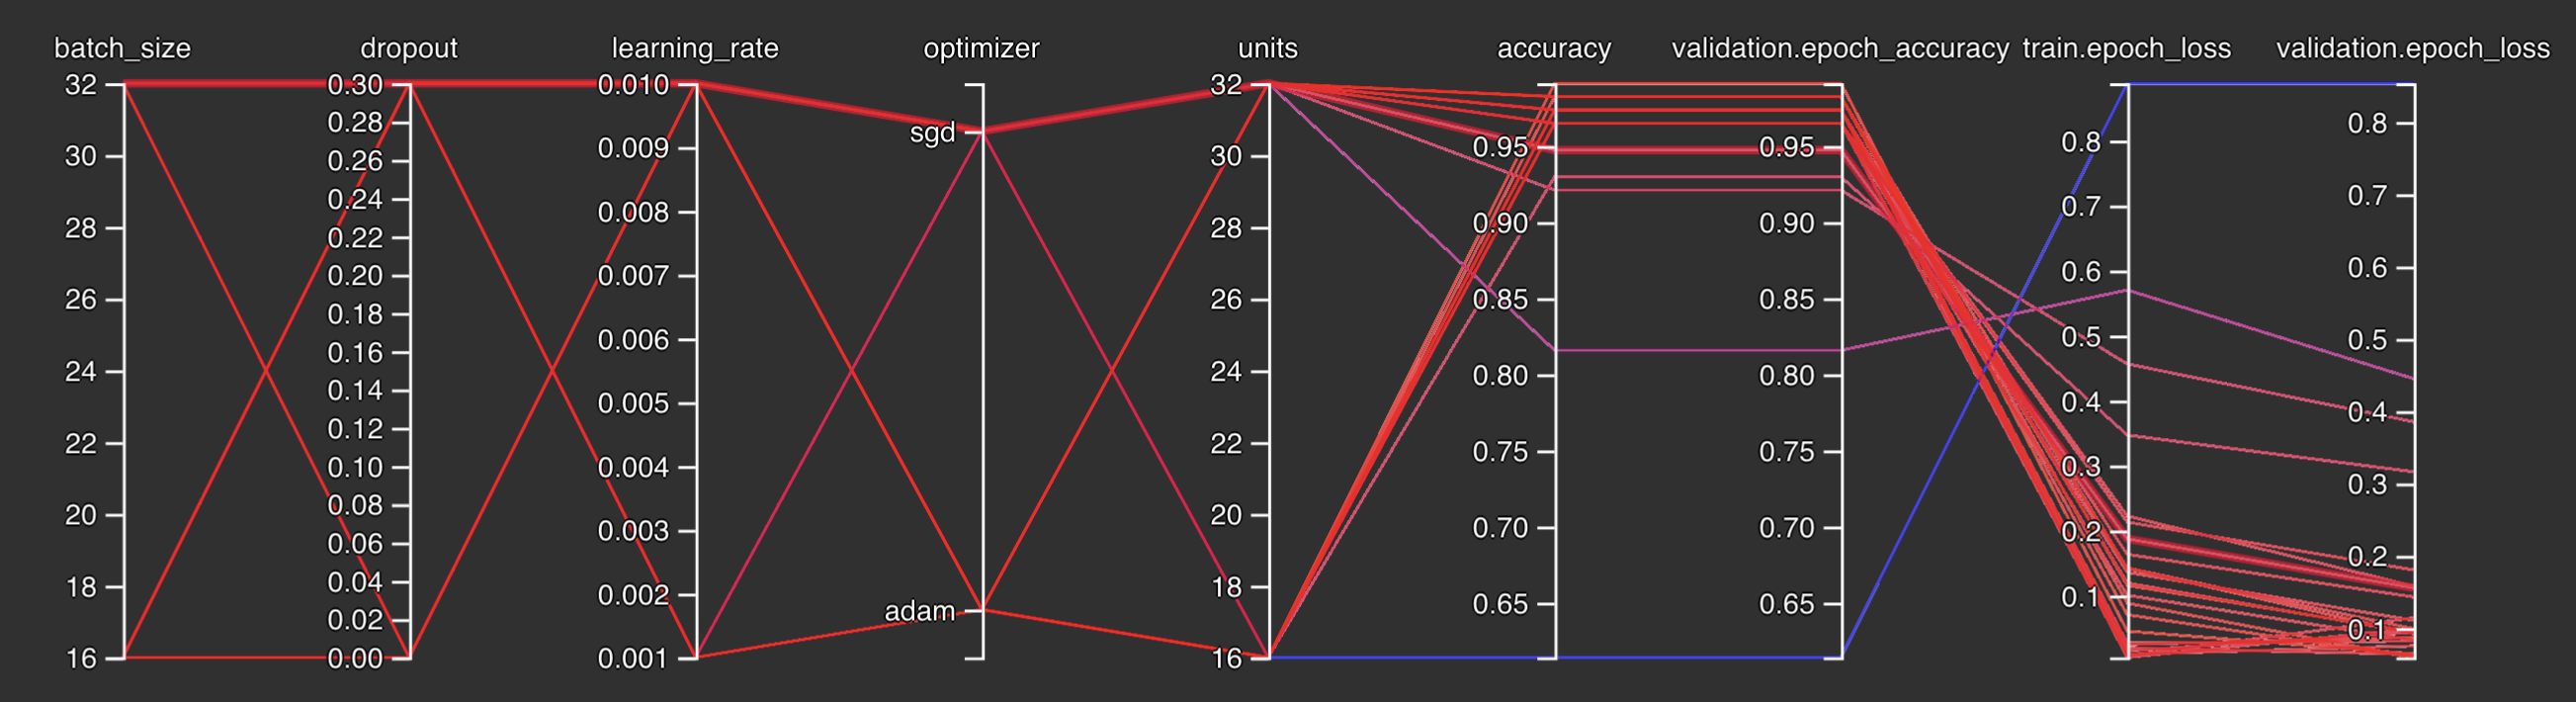

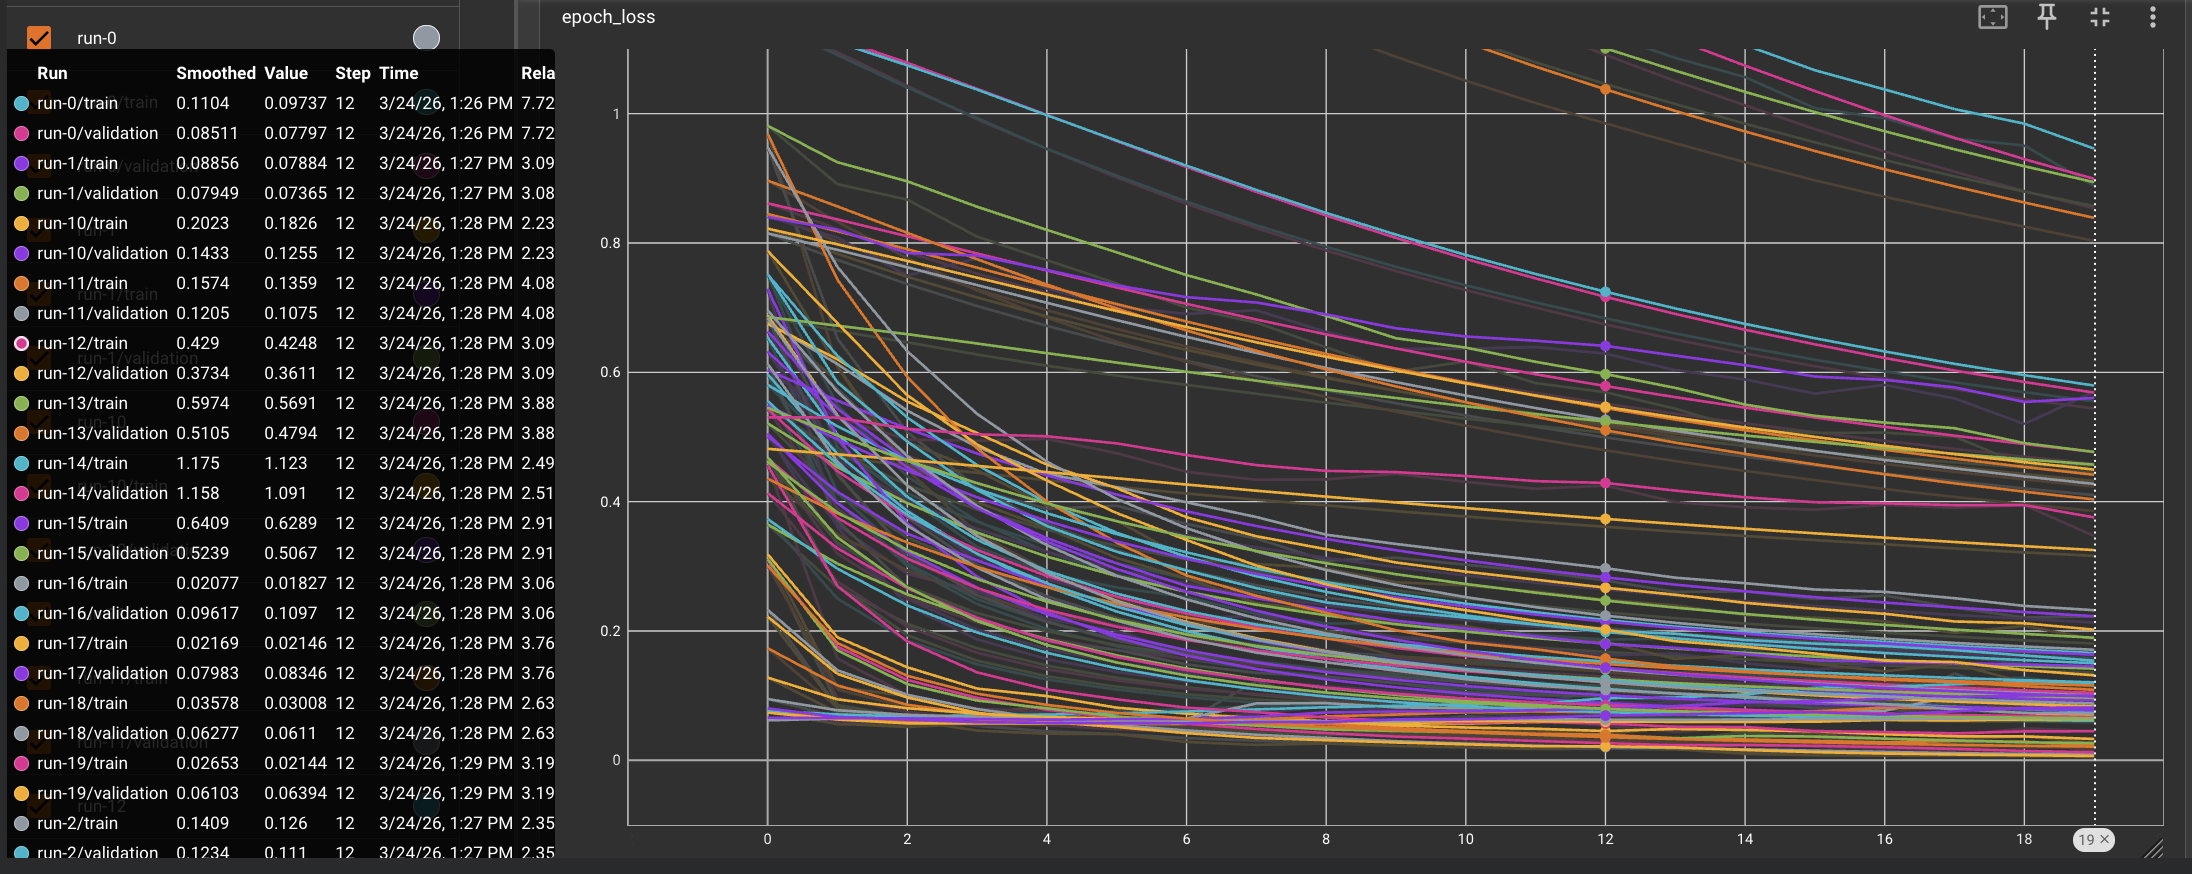

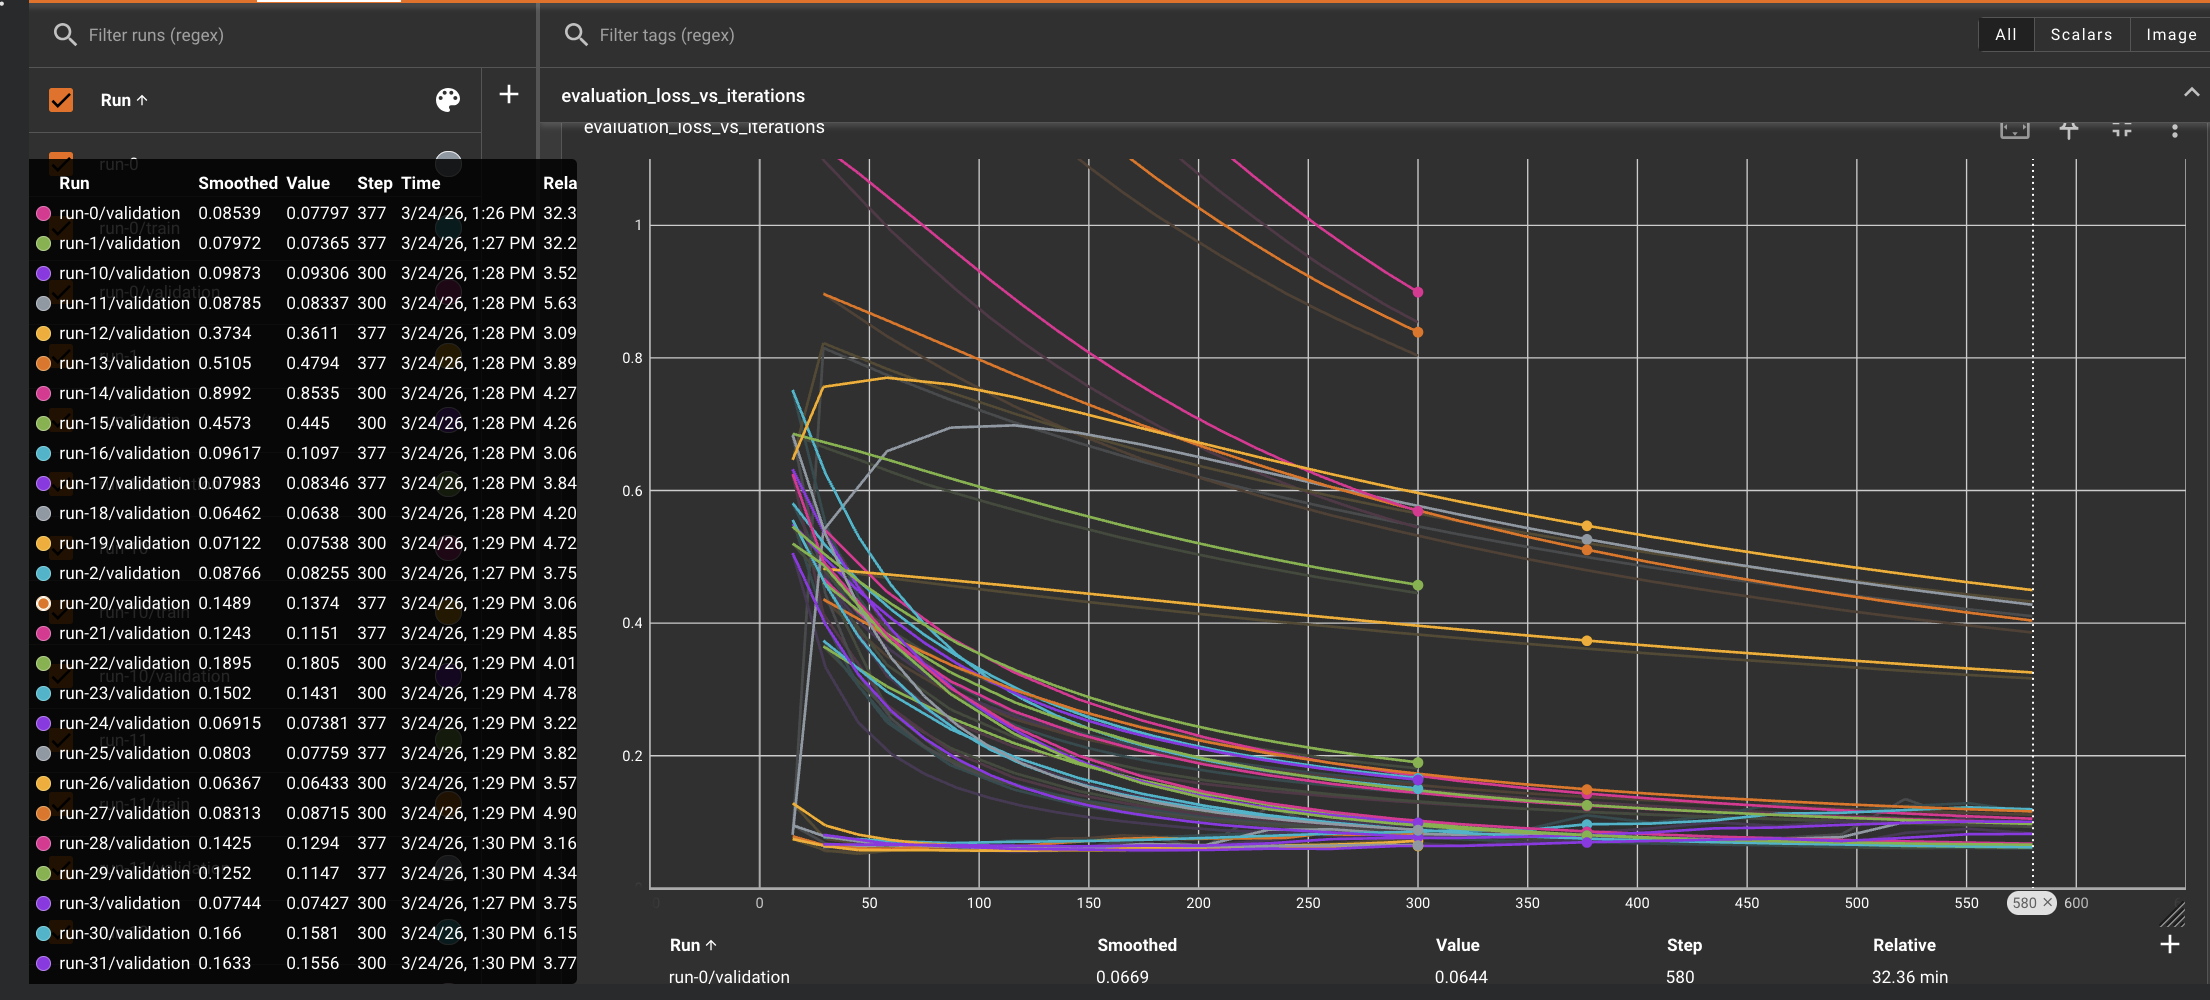



---

# B) NOW WITH KERAS TUNNING




In [ ]:
!pip install keras-tuner -q

In [ ]:
# ======================
# LIBRARIES
# ======================
import numpy as np
import keras_tuner as kt
from tensorflow import keras
from tensorflow.keras import layers


# ======================
# LOAD + PREPROCESS DATA
# ======================

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Load dataset
data = load_breast_cancer()

X = data.data          # (569, 30)
y = data.target        # (569,)

# reshape labels to (samples, 1)
y = y.reshape(-1, 1)

# train/test split
X_train, X_test, Y_train, Y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape, Y_train.shape)
print("Test:", X_test.shape, Y_test.shape)


In [ ]:
# ======================
# MODEL BUILDER (IMPORTANT)
# ======================

def build_model(hp):

    model = keras.Sequential()

    # input layer
    model.add(layers.Input(shape=(X_train.shape[1],)))

    # number of units (architecture)
    units = hp.Int('units', min_value=16, max_value=32, step=16)
    model.add(layers.Dense(units, activation='relu'))

    # dropout (regularization)
    dropout = hp.Float('dropout', min_value=0.0, max_value=0.3, step=0.3)
    model.add(layers.Dropout(dropout))

    model.add(layers.Dense(1, activation='sigmoid'))

    # learning rate
    lr = hp.Choice('learning_rate', [0.001, 0.01])

    # optimizer choice
    optimizer_name = hp.Choice('optimizer', ['adam', 'sgd'])

    if optimizer_name == 'adam':
        optimizer = keras.optimizers.Adam(learning_rate=lr)
    else:
        optimizer = keras.optimizers.SGD(learning_rate=lr)

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

# ======================
# TUNER (Random Search)
# ======================

tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',   # what to optimize
    max_trials=10,              # number of random combinations
    executions_per_trial=1,
    directory='logs/random_search',
    project_name='breast_cancer'
)

# ======================
# TENSORBOARD CALLBACK
# ======================

tensorboard_callback = keras.callbacks.TensorBoard(
    log_dir='logs/random_search/tb_logs'
)


In [ ]:
# ======================
# RUN SEARCH
# ======================

tuner.search(
    X_train, Y_train,
    validation_data=(X_test, Y_test),
    epochs=20,
    batch_size=32,   # you can also tune this, but keep fixed for now
    callbacks=[tensorboard_callback],
    verbose=1
)


In [ ]:

# ======================
# BEST RESULT
# ======================

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best hyperparameters:")
print("units:", best_hps.get('units'))
print("dropout:", best_hps.get('dropout'))
print("learning_rate:", best_hps.get('learning_rate'))
print("optimizer:", best_hps.get('optimizer'))

In [ ]:
%load_ext tensorboard

%tensorboard --logdir logs/random_search/tb_logs

# %tensorboard --logdir /tmp/tb_logs
# %tensorboard tensorboard_callback ## DONT WORK

# RESULTS B:

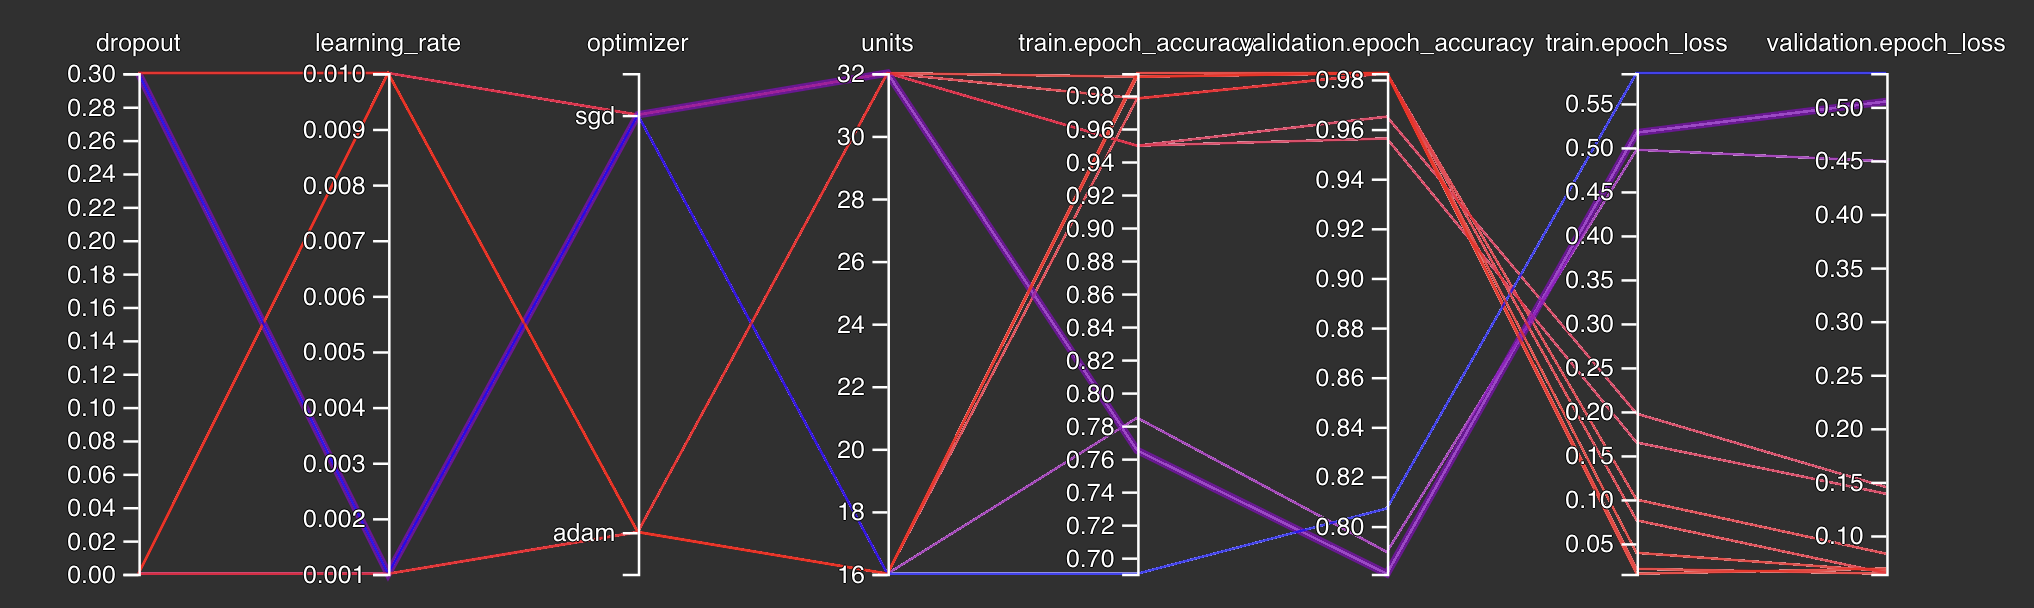

Scalars

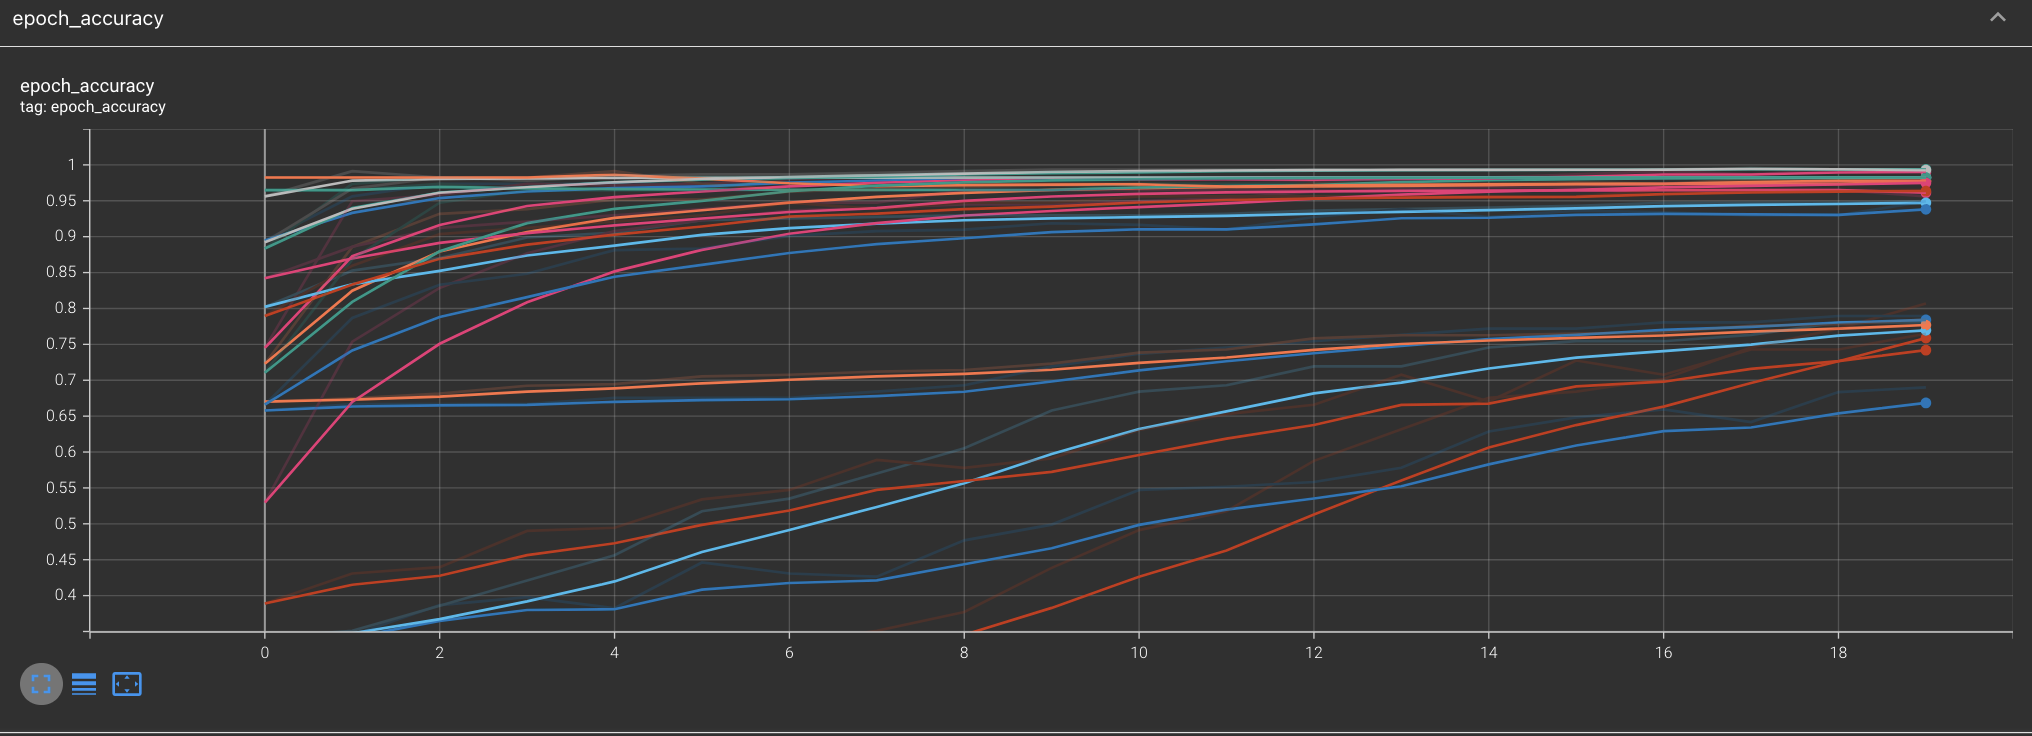

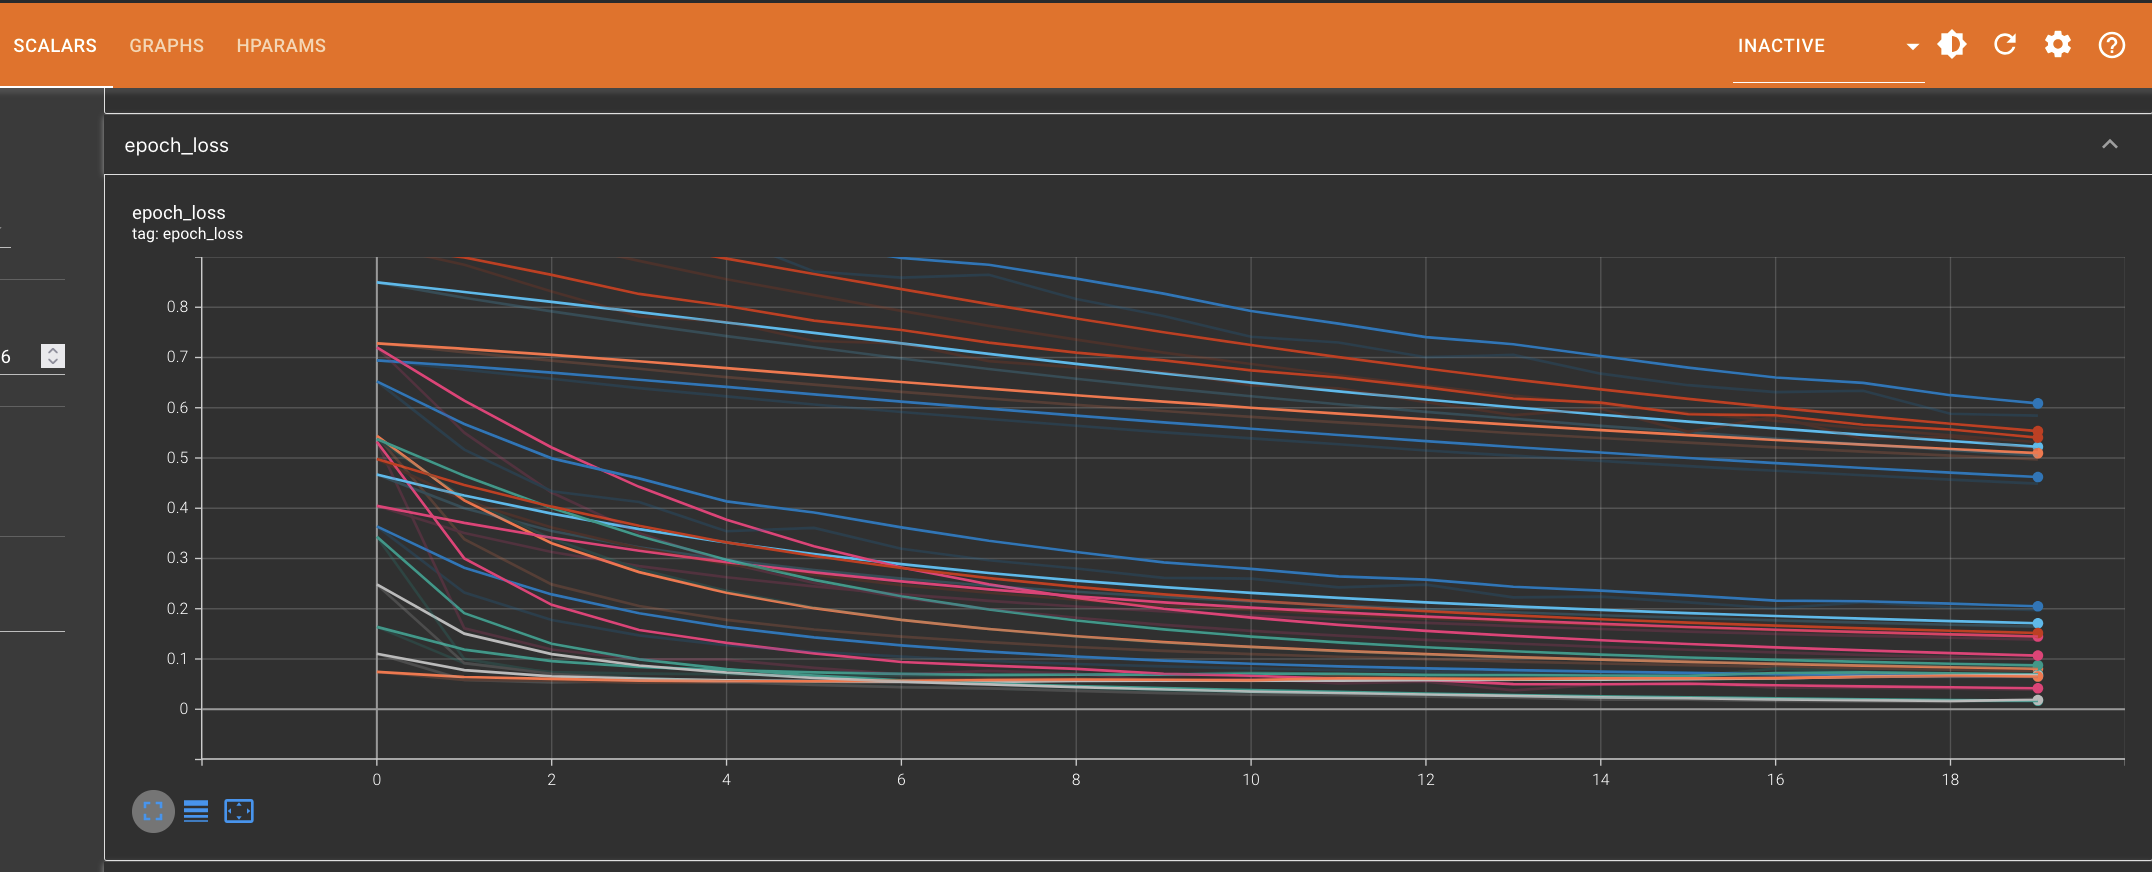

# CONCLUSION:

* Impact of Architecture and Optimization: The combination of a higher learning rate (0.01) and a slightly larger hidden layer (32 units) using the Adam optimizer proved to be the most effective strategy for this dataset.

* Regularization Findings: Interestingly, the best-performing model utilized a dropout rate of 0.0, suggesting that for the 20-epoch training duration used, additional regularization was not required to prevent overfitting and achieve high accuracy.

* Tool Effectiveness: The transition from manual Grid Search to Keras Tuner significantly streamlined the experimentation process, allowing for rapid identification of high-performing model parameters.



We can detect overfitting in both Grid Search and Keras Tuner by comparing the training metrics against the validation metrics logged during each trial.

Overfitting is identified when the training loss continues to decrease while the validation loss begins to increase or plateau, creating a "gap" between the two curves

Also, if a model achieves near 100% training accuracy but significantly lower validation accuracy (e.g., Trial 10 reached 98.25% while the best was 99.12%), it suggests that specific configuration might be starting to overfit the training data.



**HOW TO IDENTIFY OVERFITTING:**

1.- High Training Accuracy / Low Validation Accuracy: A large disparity between these two figures is a classic sign of a model that has "memorized" the training set but cannot generalize to the test set.

2.- Validation Loss Divergence: if you see the training loss curve going down while the validation loss curve starts to tick upwards, that trial is overfitting.

3.- Effect of Dropout: Analyzing the trials where HP_DROPOUT was set to 0.3 versus 0.0. If the models with 0.3 dropout had a smaller gap between training and validation performance (even if total accuracy was lower), those models were better at resisting overfitting.


CNNs tend to overfit this type of data, they work best when nearby inputs are related, like pixels in an image. In your dataset, the features are just separate numbers with no real “neighbors,” so a CNN is trying to find patterns that don’t exist. This can make it overfit or not improve performance. A simple fully connected network works better because it treats each feature independently.